In [5]:
import sqlite3
db_path = r"C:\Users\ADMIN\smart agricultural analytics\agriculture.db"
conn = sqlite3.connect(db_path)

# Check available tables
tables = pd.read_sql_query(
    """
    SELECT name
    FROM sqlite_master
    WHERE type='table';
    """,
    conn
)

print("Available tables:")
display(tables)

Available tables:


,name
0,crop_recommendation
1,agri_yield_train
2,agri_yield_test
3,crop_recommendation_clean
4,agri_yield_train_clean
5,agri_yield_test_clean
6,crop_recommendation_fe
7,agri_yield_train_fe
8,agri_yield_test_fe
9,crop_recommendation_selected


In [6]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt




sf24 = pd.read_sql_query(
    "SELECT * FROM crop_recommendation_selected",
    conn
)


# Display dataset information
print("Dataset shape:", sf24.shape)
print("\nFirst 5 rows:")
display(sf24.head())

print("\nColumn names:")
print(sf24.columns.tolist())

print("\nMissing values:")
print(sf24.isnull().sum())

Dataset shape: (2200, 13)

First 5 rows:


,humidity,K,temperature,N,P_K_Ratio,NPK_Total,Temperature_Rainfall,rainfall,N_K_Ratio,Humidity_Rainfall,Temperature_Humidity,P,label
0,82.002744,43,20.879744,90,0.976744,175,4237.241986,202.935536,2.093023,16641.270870,1712.196283,42,rice
1,80.319644,41,21.770462,85,1.414634,184,4934.395694,226.655537,2.073171,18204.892093,1748.595734,58,rice
2,82.320763,44,23.004459,60,1.250000,159,6072.354751,263.964248,1.363636,21729.738241,1893.744627,55,rice
3,80.158363,40,26.491096,74,0.875000,149,6433.734530,242.864034,1.850000,19467.583326,2123.482908,35,rice
4,81.604873,42,20.130175,78,1.000000,162,5288.545993,262.717340,1.857143,21439.015172,1642.720357,42,rice



Column names:
['humidity', 'K', 'temperature', 'N', 'P_K_Ratio', 'NPK_Total', 'Temperature_Rainfall', 'rainfall', 'N_K_Ratio', 'Humidity_Rainfall', 'Temperature_Humidity', 'P', 'label']

Missing values:
humidity                0
K                       0
temperature             0
N                       0
P_K_Ratio               0
NPK_Total               0
Temperature_Rainfall    0
rainfall                0
N_K_Ratio               0
Humidity_Rainfall       0
Temperature_Humidity    0
P                       0
label                   0
dtype: int64


,Count,Percentage
label,,
apple,100,4.55
banana,100,4.55
blackgram,100,4.55
chickpea,100,4.55
coconut,100,4.55
coffee,100,4.55
cotton,100,4.55
grapes,100,4.55
jute,100,4.55


Total records: 2200
Number of crop classes: 22
Smallest class: 100
Largest class: 100


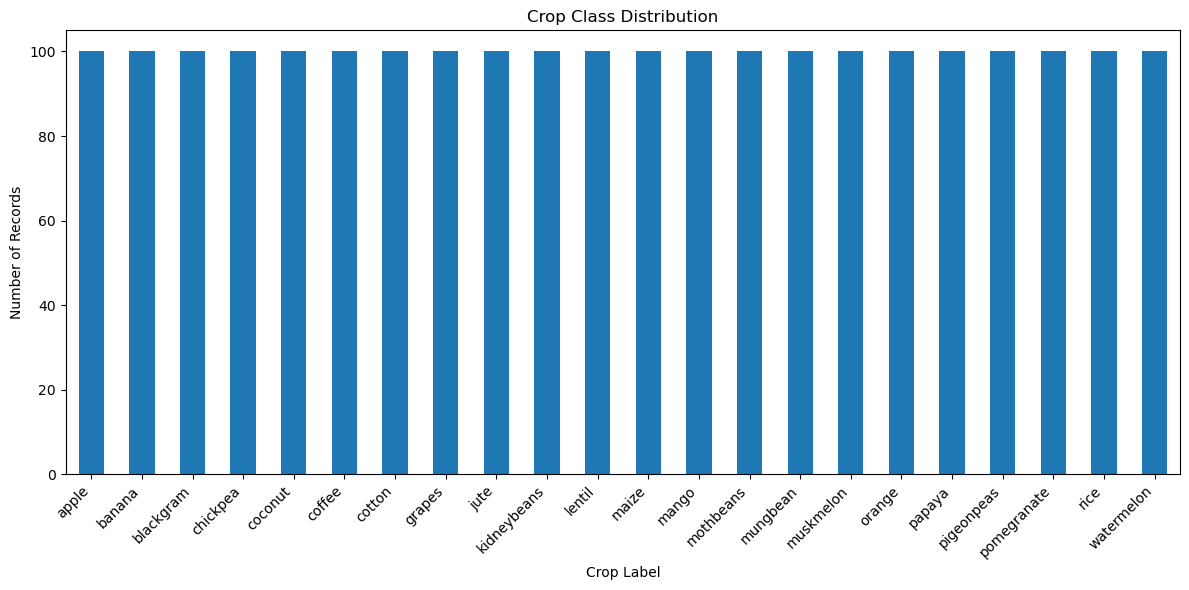

In [7]:
# Count each crop label
class_counts = sf24["label"].value_counts().sort_index()

# Calculate percentages
class_percentages = (
    sf24["label"].value_counts(normalize=True).sort_index() * 100
)

# Combine results
class_distribution = pd.DataFrame({
    "Count": class_counts,
    "Percentage": class_percentages
})

display(class_distribution.round(2))

print("Total records:", len(sf24))
print("Number of crop classes:", sf24["label"].nunique())
print("Smallest class:", class_counts.min())
print("Largest class:", class_counts.max())

# Plot class distribution
plt.figure(figsize=(12, 6))
class_counts.plot(kind="bar")

plt.title("Crop Class Distribution")
plt.xlabel("Crop Label")
plt.ylabel("Number of Records")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()